In [ ]:
import h5py
import os
import numpy as np

In [ ]:
import h5py
import numpy as np
import os



# --- CONFIGURATION ---
BASE_DIR = "/home/STORAGE/TNG50-4/groups_025"
SNAP_NUM = "025"

# Path to the first file (to read header info)
first_file = os.path.join(BASE_DIR, f"fof_subhalo_tab_{SNAP_NUM}.0.hdf5")

print(f"--> Reading Header from: {first_file}")

# 1. GET PARAMETERS FROM HEADER
with h5py.File(first_file, 'r') as f:
    header = f['Header'].attrs
    num_files = int(header['NumFiles'])      # Total number of chunks (0 to N)
    h_param = header['HubbleParam']          # Little h (e.g., 0.6774)
    scale_factor = header['Time']            # Scale factor 'a' (1/(1+z))
    
    print(f"   NumFiles: {num_files}")
    print(f"   Hubble (h): {h_param}")
    print(f"   Scale Factor (a): {scale_factor}")

# 2. LOOP OVER ALL FILES TO COLLECT RAW R200
# TNG splits data across multiple files. We must read them all.
raw_r200_list = []

print(f"--> Iterating over {num_files} files...")

for i in range(num_files):
    # Construct filename for current chunk
    filename = os.path.join(BASE_DIR, f"fof_subhalo_tab_{SNAP_NUM}.{i}.hdf5")
    
    with h5py.File(filename, 'r') as f:
        # Check if this file actually contains groups
        if 'Group' in f and 'Group_R_Crit200' in f['Group']:
            # Read the dataset
            chunk_data = f['Group']['Group_R_Crit200'][:]
            raw_r200_list.append(chunk_data)

# 3. CONCATENATE AND CONVERT UNITS
if len(raw_r200_list) > 0:
    # Merge list of arrays into one big numpy array
    all_r200_code = np.concatenate(raw_r200_list)
    
    # --- UNIT CONVERSION ---
    # Native TNG Unit: ckpc/h (Comoving kiloparsecs / h)
    # Target Unit:     Mpc (Physical Megaparsecs)
    
    # Formula: Value * (scale_factor / h) / 1000
    all_r200_mpc = (all_r200_code / 1000.0) * scale_factor / h_param
    
    print("-" * 30)
    print(f"RESULTS (Physical Mpc):")
    print(f"Total Halos Found: {len(all_r200_mpc)}")
    print(f"Min R200:  {np.min(all_r200_mpc):.6f} Mpc")
    print(f"Max R200:  {np.max(all_r200_mpc):.6f} Mpc")
    print(f"Mean R200: {np.mean(all_r200_mpc):.6f} Mpc")
    print("-" * 30)
    
    # Example: Print first 10
    print(f"First 10 values: {all_r200_mpc[:10]}")

else:
    print("[ERROR] No R200 data found in any file.")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

# --- CONFIGURAÇÃO DE PLOT (Estilo do seu código) ---
font = {'family' : 'serif', 'weight' : 'normal', 'size' : 14}
rcnew = {
    "mathtext.fontset" : "cm", "text.usetex": False, 'figure.frameon': True,
    'axes.linewidth': 2., "axes.titlesize" : 18, "axes.labelsize" : 18,
    "legend.fontsize" : 14, 'legend.fancybox': True, 'lines.linewidth': 1.5,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True
}
plt.rc('font', **font)
plt.rcParams.update(rcnew)

# --- 1. CONFIGURAÇÕES INICIAIS ---
FILE_FID = "fiducial_452Halos_FullSpectra_new.pkl" # Atualizado para o nome que você tem
FILE_LH0 = "LH_0_452Halos_FullSpectra.pkl"
FILE_LH1 = "LH_1_452Halos_FullSpectra.pkl"

TARGET_RADII = [0.1, 0.2, 0.5, 1.3, 3.0]
SKEWER_TO_PLOT = 1 # Escolha qual skewer plotar (1 a 12)

LAMBDA_REST = 1215.67 # Angstroms

# --- 2. CARREGAR DADOS ---
print(f"--> Carregando dados...")
df_fid = pd.read_pickle(FILE_FID)
df_lh0 = pd.read_pickle(FILE_LH0)
df_lh1 = pd.read_pickle(FILE_LH1)

# Pega os halos que existem nos três catálogos
halos_comuns = list(
    set(df_fid['match_index'])
    .intersection(set(df_lh0['match_index']))
    .intersection(set(df_lh1['match_index']))
)

if not halos_comuns:
    raise ValueError("Nenhum halo em comum encontrado entre os três arquivos.")

# Seleciona um halo aleatório
random_match_index = random.choice(halos_comuns)
print(f"--> Halo Selecionado (Match Index): {random_match_index}")

# Filtra os dataframes para este halo e skewer específico
df_halo_fid = df_fid[(df_fid['match_index'] == random_match_index) & (df_fid['skewer_id'] == SKEWER_TO_PLOT)]
df_halo_lh0 = df_lh0[(df_lh0['match_index'] == random_match_index) & (df_lh0['skewer_id'] == SKEWER_TO_PLOT)]
df_halo_lh1 = df_lh1[(df_lh1['match_index'] == random_match_index) & (df_lh1['skewer_id'] == SKEWER_TO_PLOT)]

halo_mass = df_halo_fid['halo_mass'].iloc[0] if not df_halo_fid.empty else 0
print(f"--> Skewer ID: {SKEWER_TO_PLOT} | Massa do Halo (Fiducial): ~ 10^{np.log10(halo_mass * 1e10 / 0.6774):.1f} Msun")

# --- 3. CONFIGURAR O PLOT ---
fig, axes = plt.subplots(len(TARGET_RADII), 1, figsize=(8, 14), sharex=True, sharey=True)
fig.subplots_adjust(hspace=0.05) # Remove espaço entre os painéis

# Usa os raios disponíveis no fiducial como base
available_radii = np.sort(df_halo_fid['r_multiplier'].unique())

for ax, target_r in zip(axes, TARGET_RADII):
    # Encontra o raio disponível mais próximo do alvo
    closest_r = available_radii[np.abs(available_radii - target_r).argmin()]
    
    # Extrai e plota Fiducial
    row_fid = df_halo_fid[df_halo_fid['r_multiplier'] == closest_r]
    if not row_fid.empty:
        ax.plot(row_fid['wave'].iloc[0], row_fid['flux'].iloc[0], label='Fiducial', color='tab:blue', alpha=0.8)

    # Extrai e plota LH_0
    row_lh0 = df_halo_lh0[df_halo_lh0['r_multiplier'] == closest_r]
    if not row_lh0.empty:
        ax.plot(row_lh0['wave'].iloc[0], row_lh0['flux'].iloc[0], label='LH_0', color='tab:orange', alpha=0.8)

    # Extrai e plota LH_1
    row_lh1 = df_halo_lh1[df_halo_lh1['r_multiplier'] == closest_r]
    if not row_lh1.empty:
        ax.plot(row_lh1['wave'].iloc[0], row_lh1['flux'].iloc[0], label='LH_1', color='tab:green', alpha=0.8)

    # Estilização do eixo (Grid, limites, etc)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.axhline(1.0, color='gray', linestyle=':', lw=1)
    ax.axhline(0.0, color='gray', linestyle=':', lw=1)
    ax.axvline(LAMBDA_REST, color='black', linestyle='--', alpha=0.3) # Ly-alpha rest
    
    ax.set_ylim(-0.05, 1.05)
    
    # Caixa de texto com o parâmetro de impacto
    props = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='lightgray')
    ax.text(0.03, 0.1, f"$b = {target_r}$ $R_{{200}}$", transform=ax.transAxes, fontsize=12, bbox=props)

# Título principal e Legenda
axes[0].set_title(f"Skewer Comparativo | Halo Match: {random_match_index}")
axes[0].legend(loc='lower right', frameon=True)

# Labels dos eixos
axes[-1].set_xlabel(r"Wavelength $\lambda\ [\AA]$")
fig.text(0.04, 0.5, r"Normalized Flux ($F/F_0$)", va='center', rotation='vertical', fontsize=18)

# Define limites de comprimento de onda para simular a janela de +/- 1500 km/s (~ 6 Angstroms)
axes[-1].set_xlim(LAMBDA_REST - 6.5, LAMBDA_REST + 6.5)

plt.show()

In [ ]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Importing fake_spectra modules
from fake_spectra.spectra import Spectra
import fake_spectra.abstractsnapshot as absn

# ==========================================
# Configuration
# ==========================================
base_dir = "/home/STORAGE/TNG50-4"
snap_num = 25
halo_id = 24005  # Target Halo ID (Global)
slice_width_mpc = 2.0  # Width of the z-slice for the map in Mpc/h

# ==========================================
# 1. Smart Halo Search Function
# ==========================================
def get_halo_info(base_dir, snap_num, target_id):
    """
    Searches for the position and mass of a halo across all chunks of the group catalog.
    """
    group_dir = os.path.join(base_dir, f"groups_{snap_num:03d}")
    
    # Read the first file to get global catalog properties
    file0 = os.path.join(group_dir, f"fof_subhalo_tab_{snap_num:03d}.0.hdf5")
    with h5py.File(file0, 'r') as f:
        num_files = f['Header'].attrs['NumFiles']
        total_halos = f['Header'].attrs['Ngroups_Total']
        
    if target_id >= total_halos:
        raise ValueError(f"Invalid ID {target_id}. Absolute maximum is {total_halos - 1}.")
        
    current_id_offset = 0
    
    # Iterate through chunks to find the specific halo
    for i in range(num_files):
        filepath = os.path.join(group_dir, f"fof_subhalo_tab_{snap_num:03d}.{i}.hdf5")
        with h5py.File(filepath, 'r') as f:
            if 'Group' not in f or 'GroupMass' not in f['Group']:
                continue
                
            n_halos = len(f['Group/GroupMass'])
            
            # Check if our target halo is within this chunk
            if target_id < current_id_offset + n_halos:
                local_index = target_id - current_id_offset
                pos = f['Group/GroupPos'][local_index]
                mass = f['Group/GroupMass'][local_index]
                print(f"Success: Halo {target_id} found in chunk .{i}.hdf5")
                return pos, mass
            
            current_id_offset += n_halos

# Extract halo data
halo_pos_kpc, halo_mass = get_halo_info(base_dir, snap_num, halo_id)
halo_pos_mpc = halo_pos_kpc / 1000.0

# ==========================================
# 2. Get Gas Positions for the 2D Map
# ==========================================
print("Loading gas particles for the map...")
snap = absn.AbstractSnapshotFactory(snap_num, base_dir)

# Read all gas coordinates (segment=-1)
gas_pos_kpc = snap.get_data(0, "Coordinates", segment=-1) 
gas_pos_mpc = gas_pos_kpc / 1000.0

# Filter particles within the specific z-slice (Halo Z +/- slice_width/2)
z_min = halo_pos_mpc[2] - (slice_width_mpc / 2.0)
z_max = halo_pos_mpc[2] + (slice_width_mpc / 2.0)

mask = (gas_pos_mpc[:, 2] >= z_min) & (gas_pos_mpc[:, 2] <= z_max)
slice_x = gas_pos_mpc[mask, 0]
slice_y = gas_pos_mpc[mask, 1]

# ==========================================
# 3. Generate the Lyman-alpha Spectrum
# ==========================================
print("Generating spectra along the x-axis (in-memory only)...")
cofm = np.array([halo_pos_kpc])
axis = np.array([1]) # X-axis sightline

# Initialize Spectra. 
# reload_file=True forces calculation from the snapshot.
# We omit spec.save_file() entirely so nothing is written to disk.
spec = Spectra(
    snap_num, 
    base_dir, 
    cofm, 
    axis, 
    res=1.0, 
    savedir=".", # Dummy path, won't be used since we don't call save_file()
    savefile="dummy.hdf5", 
    reload_file=True
)

# Compute optical depth and flux entirely in RAM
tau = spec.get_tau("H", 1, 1215)[0]
flux = np.exp(-tau)

# Create velocity array for the x-axis
vel_axis = np.linspace(0, spec.vmax, len(flux))

# ==========================================
# 4. Plotting
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

# --- Top Plot: 2D Gas Density Map ---
h = ax1.hist2d(slice_x, slice_y, bins=600, cmap='viridis', norm=LogNorm())
fig.colorbar(h[3], ax=ax1, label='Particle Count (Proxy for Density)')

# Plot skewer trajectory
ax1.axhline(y=halo_pos_mpc[1], color='red', linestyle='--', linewidth=1.5, 
            label=f'Skewer (y={halo_pos_mpc[1]:.2f} Mpc/h)')
# Plot halo center
ax1.plot(halo_pos_mpc[0], halo_pos_mpc[1], 'rX', markersize=10, label='Halo Center')

ax1.set_title(f"Gas Slice (z={halo_pos_mpc[2]:.2f} ± {slice_width_mpc/2} Mpc/h) | Halo Mass: {halo_mass:.2f} x 10^10 M_sun/h")
ax1.set_xlabel("x [Mpc/h]")
ax1.set_ylabel("y [Mpc/h]")
ax1.legend(loc='upper right')
ax1.set_aspect('equal')

# --- Bottom Plot: Lyman-alpha Flux ---
ax2.plot(vel_axis, flux, color='black', linewidth=1.0)
ax2.set_title(f"Lyman-alpha Flux along the Skewer (Halo {halo_id})")
ax2.set_xlabel("Velocity [km/s]")
ax2.set_ylabel("Transmitted Flux (e^-tau)")
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [1]:
import pandas as pd

# Caminho para o arquivo que acabou de ser gerado
file_path = '/home/vroberto/FakeSpectra_DLAs/notebooks/fiducial_1Halos_DLAMode_FullMap.pkl'

# Lendo o arquivo pickle de volta para um DataFrame
df = pd.read_pickle(file_path)

# Dando uma olhada nas primeiras linhas e nas colunas disponíveis
display(df.head())

# Para ver informações sobre a memória e os tipos de dados (incluindo seus arrays nativos)
df.info()

,match_index,halo_id,halo_mass,halo_r200_mpc,redshift,skewer_id,axis,r_multiplier,impact_kpc,log_n_hi,...,skewness,kurtosis,mean_wave,mean_vel,vel_coherent,wave,flux,vel_axis,chi_axis,n_hi_col
0,0,4256,22.753996,0.145181,2.978398,1,0,0.0,0.000000,23.474593,...,-0.001898,1.924781,1215.802660,32.713066,-24.352096,"[1106.523, 1106.5599, 1106.5968, 1106.6338, 11...","[0.4247555, 0.42483994, 0.42503095, 0.42521793...","[-28202.295, -28192.291, -28182.29, -28172.287...","[-250.0, -249.91133, -249.82266, -249.734, -24...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
1,0,4256,22.753996,0.145181,2.978398,2,1,0.0,0.000000,23.184784,...,0.014597,2.112358,1214.812745,-211.479374,50.489584,"[1106.523, 1106.5599, 1106.5968, 1106.6338, 11...","[0.63824254, 0.638047, 0.63784057, 0.637634, 0...","[-28202.295, -28192.291, -28182.29, -28172.287...","[-250.0, -249.91133, -249.82266, -249.734, -24...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
2,0,4256,22.753996,0.145181,2.978398,3,2,0.0,0.000000,23.372549,...,-0.000282,1.978617,1215.688605,4.587984,4.880828,"[1106.523, 1106.5599, 1106.5968, 1106.6338, 11...","[0.50891113, 0.50890315, 0.50887793, 0.5088431...","[-28202.295, -28192.291, -28182.29, -28172.287...","[-250.0, -249.91133, -249.82266, -249.734, -24...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
3,0,4256,22.753996,0.145181,2.978398,1,0,0.1,14.518137,21.082406,...,-0.038820,11.154816,1216.453141,193.065671,-24.751996,"[1106.523, 1106.5599, 1106.5968, 1106.6338, 11...","[0.99651116, 0.99651223, 0.99651474, 0.9965172...","[-28202.295, -28192.291, -28182.29, -28172.287...","[-250.0, -249.91133, -249.82266, -249.734, -24...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
4,0,4256,22.753996,0.145181,2.978398,2,0,0.1,14.518137,21.291992,...,0.000447,9.001146,1215.653547,-4.057552,-22.279814,"[1106.523, 1106.5599, 1106.5968, 1106.6338, 11...","[0.9943866, 0.9943859, 0.99438435, 0.99438274,...","[-28202.295, -28192.291, -28182.29, -28172.287...","[-250.0, -249.91133, -249.82266, -249.734, -24...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   match_index    63 non-null     int64  
 1   halo_id        63 non-null     int64  
 2   halo_mass      63 non-null     float32
 3   halo_r200_mpc  63 non-null     float32
 4   redshift       63 non-null     float64
 5   skewer_id      63 non-null     int64  
 6   axis           63 non-null     int64  
 7   r_multiplier   63 non-null     float64
 8   impact_kpc     63 non-null     float64
 9   log_n_hi       63 non-null     float64
 10  total_col_den  63 non-null     float64
 11  eq_width       63 non-null     float64
 12  std_dev        63 non-null     float64
 13  skewness       63 non-null     float64
 14  kurtosis       63 non-null     float64
 15  mean_wave      63 non-null     float64
 16  mean_vel       63 non-null     float64
 17  vel_coherent   63 non-null     float64
 18  wave        

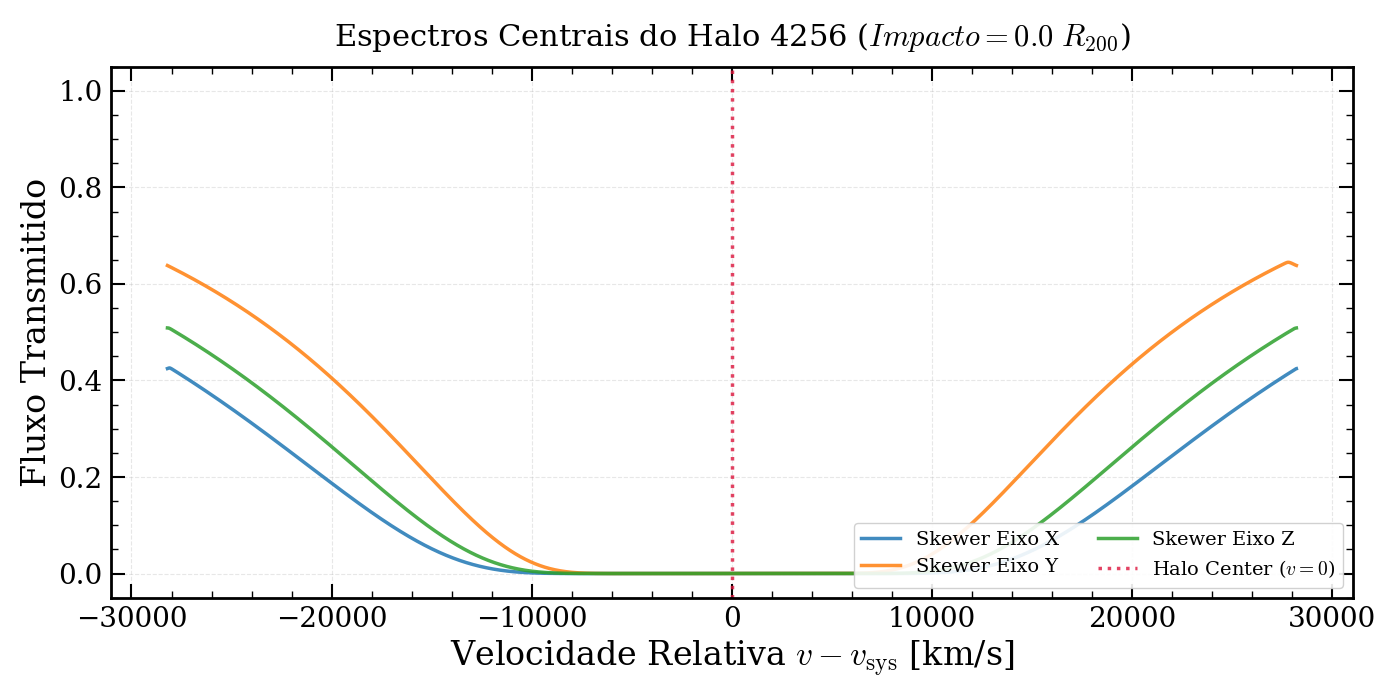

In [2]:
%matplotlib widget 
import matplotlib.pyplot as plt
import numpy as np

# --- CONFIGURAÇÃO DE ESTILO DO PLOT ---
def matplotlib_default_config():
    font = {'family' : 'serif', 'weight' : 'normal', 'size'   : 14}
    rcnew = {
        "mathtext.fontset" : "cm", "text.usetex": False, 'figure.frameon': True,
        'axes.linewidth': 2., "axes.titlesize" : 24, "axes.labelsize" : 24,
        "legend.fontsize" : 16, 'legend.fancybox': True, 'lines.linewidth': 2.5,
        'xtick.alignment': 'center', 'xtick.bottom': True, 'xtick.color': 'black',
        'xtick.direction': 'in', 'xtick.labelbottom': True, 'xtick.labelsize': 20,
        'xtick.major.bottom': True, 'xtick.major.pad': 6.0, 'xtick.major.size': 10.0,
        'xtick.major.width': 1.5, 'xtick.minor.bottom': True, 'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0, 'xtick.minor.visible': True, 'xtick.minor.width': 1.0,
        'xtick.top': True, 'ytick.alignment': 'center_baseline', 'ytick.color': 'black',
        'ytick.direction': 'in', 'ytick.labelleft': True, 'ytick.labelsize': 20,
        'ytick.left': True, 'ytick.major.left': True, 'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0, 'ytick.major.width': 1.5, 'ytick.minor.left': True,
        'ytick.minor.pad': 3.4, 'ytick.minor.right': True, 'ytick.minor.size': 5.0,
        'ytick.minor.visible': True, 'ytick.minor.width': 1.0, 'ytick.right': True
    }
    return font, rcnew

font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)


# --- LÓGICA DO PLOT CENTRAL ---
# Filtra o DataFrame APENAS para o impacto zero (Centro do Halo)
df_center = df[np.isclose(df['r_multiplier'], 0.0)].copy()

# Ordena pelo eixo para garantir que as cores sempre correspondam ao mesmo eixo (0=X, 1=Y, 2=Z)
df_center = df_center.sort_values(by='axis')

# Criando a figura com um único painel largo
fig, ax = plt.subplots(figsize=(14, 7))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c'] 
eixos_nomes = ['X', 'Y', 'Z']

# Plota os 3 skewers centrais sobrepostos
for (idx, row), color, eixo in zip(df_center.iterrows(), colors, eixos_nomes):
    ax.plot(row['vel_axis'], row['flux'], lw=2.5, alpha=0.85, 
            color=color, label=f"Skewer Eixo {eixo}")
    
# Marcação do centro cinemático do Halo
ax.axvline(0.0, color='crimson', linestyle=':', lw=2.5, alpha=0.8, label='Halo Center ($v=0$)')

ax.set_ylabel('Fluxo Transmitido')
ax.set_xlabel(r'Velocidade Relativa $v - v_{\mathrm{sys}}$ [km/s]')
ax.set_ylim(-0.05, 1.05)

# Zoom focado na região do DLA (ajuste o limite se as asas forem muito grandes)
#ax.set_xlim(-1500, 1500) 

ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='lower right', fontsize=14, framealpha=0.9, ncol=2)

halo_id_title = df_center['halo_id'].iloc[0]
plt.title(f"Espectros Centrais do Halo {halo_id_title} ($Impacto = 0.0 \ R_{{200}}$)", fontsize=22, pad=15)

plt.tight_layout()
plt.show()

/tmp/ipykernel_988002/1228765681.py:61: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  skewers_to_plot = df_r.groupby('axis').apply(lambda x: x.sample(n=2, random_state=42)).reset_index(drop=True)
/tmp/ipykernel_988002/1228765681.py:61: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  skewers_to_plot = df_r.groupby('axis').apply(lambda x: x.sample(n=2, random_state=42)).reset_index(drop=True)
/tmp/ipykernel_988002/122876

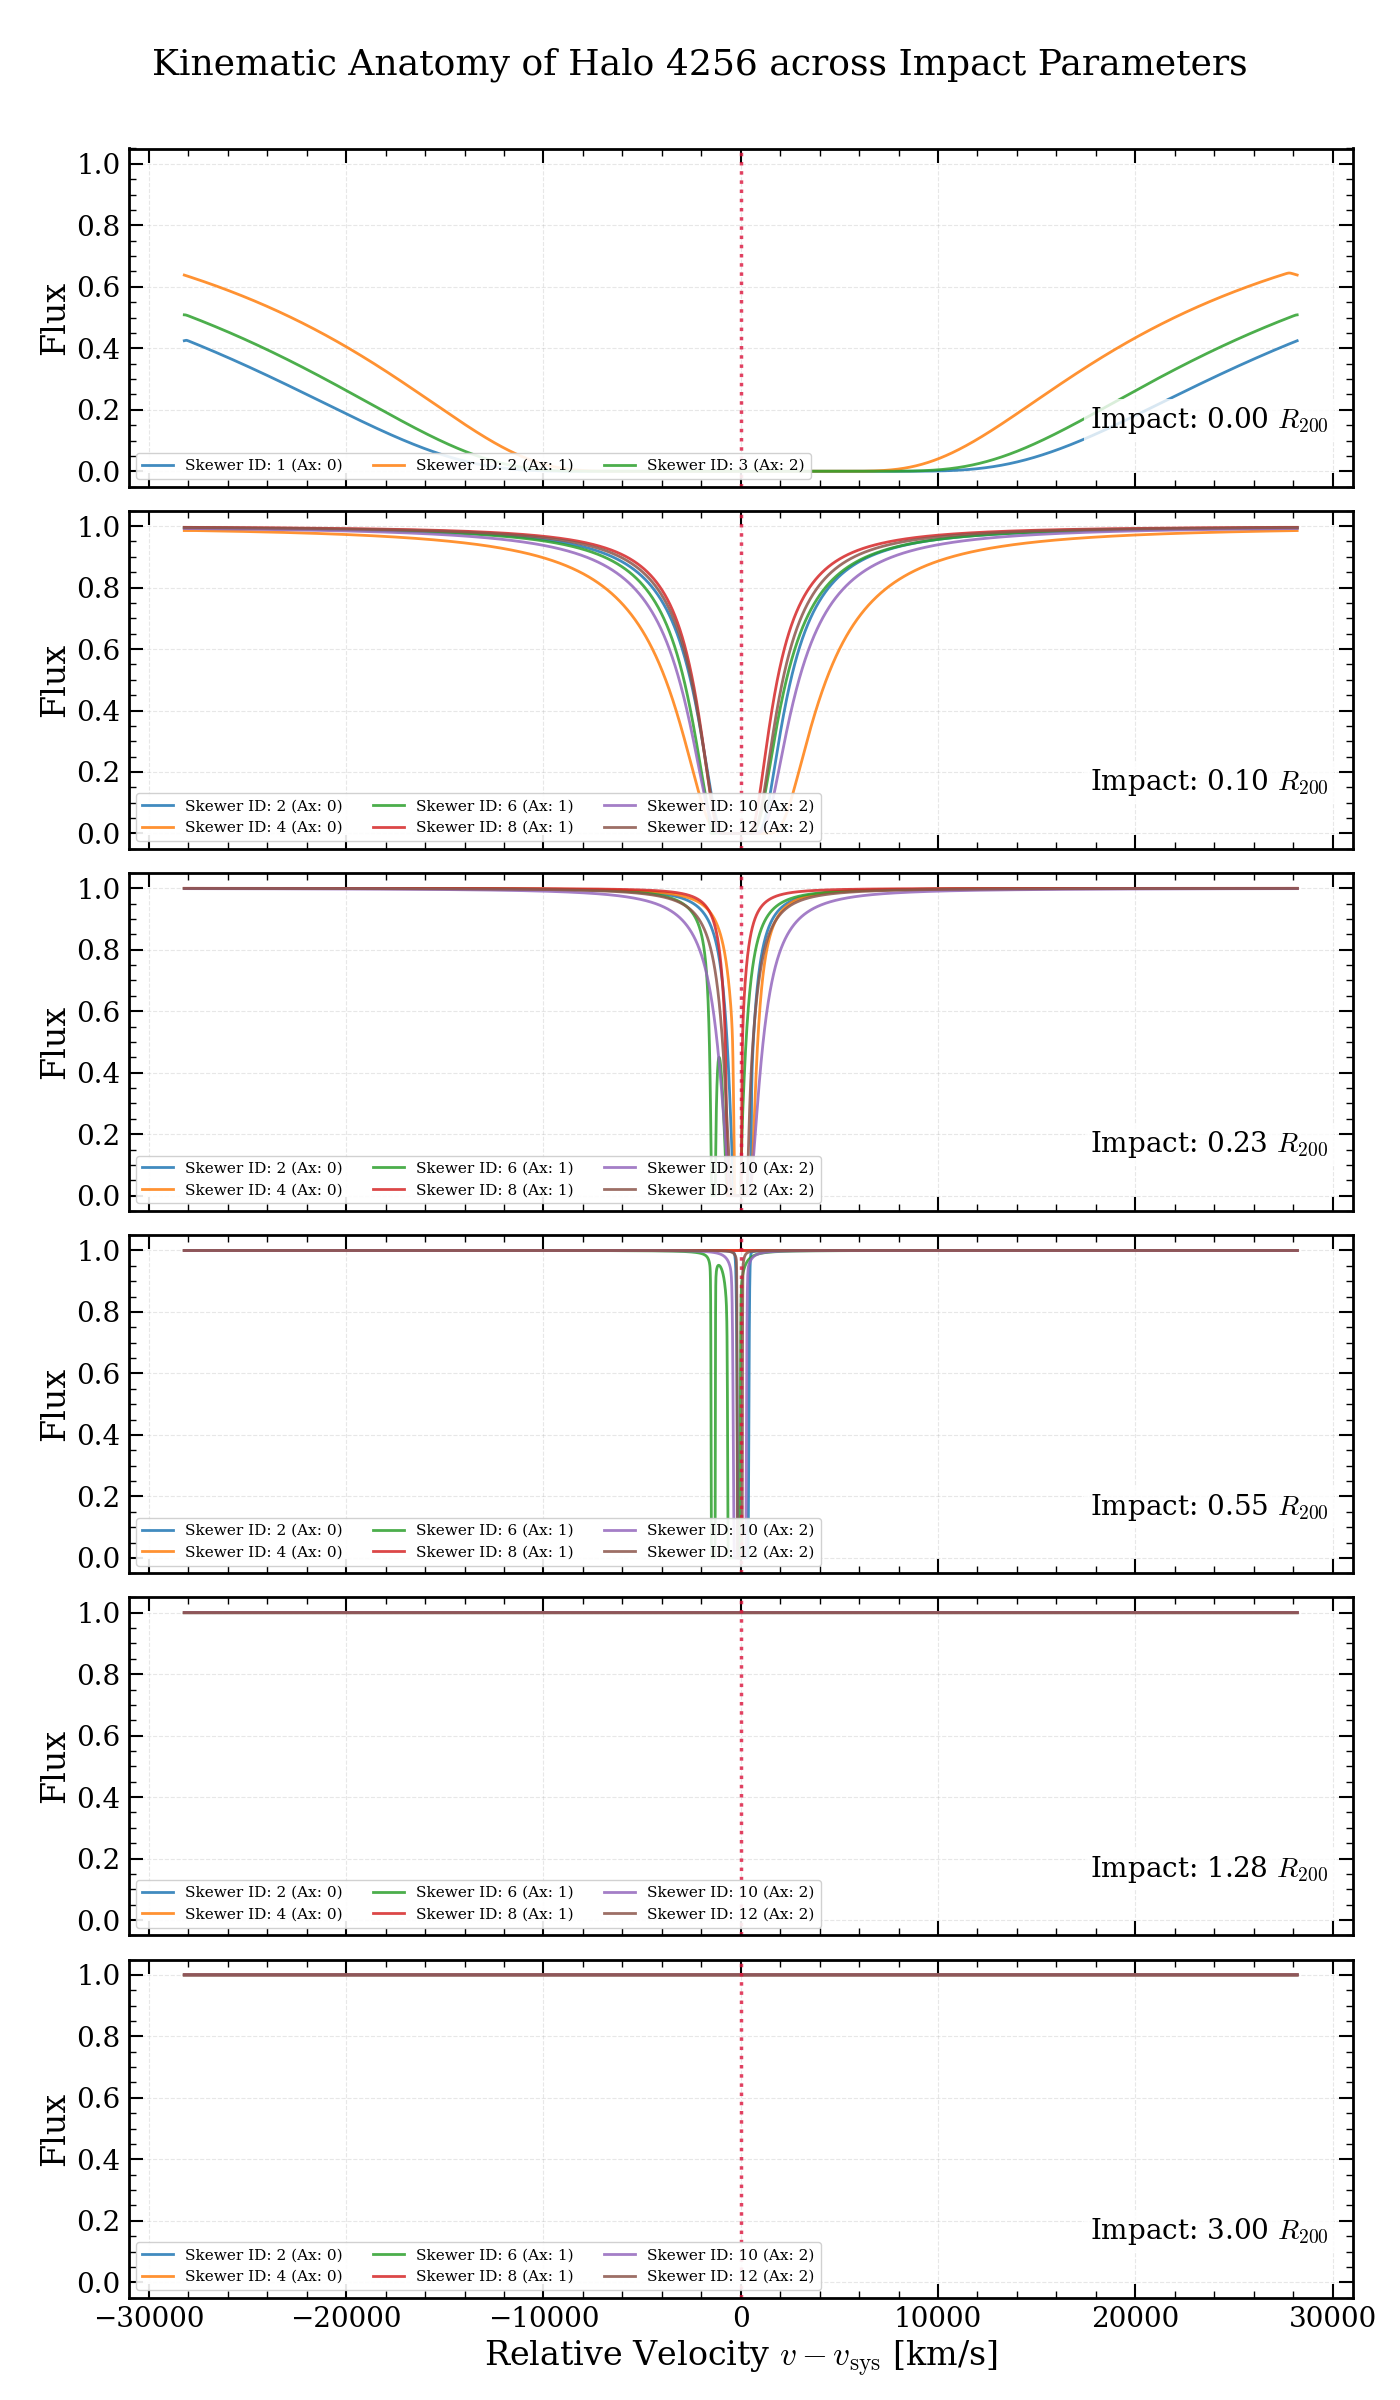

In [5]:
# ==============================================================================
# CELL 10: STACKED SPECTRA BY IMPACT PARAMETER
# ==============================================================================
%matplotlib widget 
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load the parallel pipeline output DataFrame
file_path = '/home/vroberto/FakeSpectra_DLAs/notebooks/fiducial_1Halos_DLAMode_FullMap.pkl'
df = pd.read_pickle(file_path)

# --- PLOT STYLE CONFIGURATION ---
def matplotlib_default_config():
    """Applies a clean, publication-ready style for matplotlib."""
    font = {'family' : 'serif', 'weight' : 'normal', 'size'   : 14}
    rcnew = {
        "mathtext.fontset" : "cm", "text.usetex": False, 'figure.frameon': True,
        'axes.linewidth': 2., "axes.titlesize" : 24, "axes.labelsize" : 24,
        "legend.fontsize" : 14, 'legend.fancybox': True, 'lines.linewidth': 2.0,
        'xtick.alignment': 'center', 'xtick.bottom': True, 'xtick.color': 'black',
        'xtick.direction': 'in', 'xtick.labelbottom': True, 'xtick.labelsize': 20,
        'xtick.major.bottom': True, 'xtick.major.pad': 6.0, 'xtick.major.size': 10.0,
        'xtick.major.width': 1.5, 'xtick.minor.bottom': True, 'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0, 'xtick.minor.visible': True, 'xtick.minor.width': 1.0,
        'xtick.top': True, 'ytick.alignment': 'center_baseline', 'ytick.color': 'black',
        'ytick.direction': 'in', 'ytick.labelleft': True, 'ytick.labelsize': 20,
        'ytick.left': True, 'ytick.major.left': True, 'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0, 'ytick.major.width': 1.5, 'ytick.minor.left': True,
        'ytick.minor.pad': 3.4, 'ytick.minor.right': True, 'ytick.minor.size': 5.0,
        'ytick.minor.visible': True, 'ytick.minor.width': 1.0, 'ytick.right': True
    }
    return font, rcnew

font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

# --- PLOTTING LOGIC ---
# Extract unique sorted impact parameters
r_mults = sorted(df['r_multiplier'].unique())

# Create a figure with 6 stacked panels
fig, axes = plt.subplots(nrows=6, ncols=1, figsize=(14, 24), sharex=True)

# Color palette (up to 6 distinct colors for the off-center skewers)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

for i, r in enumerate(r_mults):
    ax = axes[i]
    
    # Filter the DataFrame safely for the current impact parameter
    df_r = df[np.isclose(df['r_multiplier'], r)].copy()
    
    if np.isclose(r, 0.0):
        # For r=0.0, we just take all 3 central skewers
        skewers_to_plot = df_r.sort_values(by='axis')
    else:
        # For r>0.0, we have 12 skewers. We group by axis (X, Y, Z) and pick 2 from each,
        # yielding exactly 6 skewers that represent all 3D "faces" of the halo environment.
        skewers_to_plot = df_r.groupby('axis').apply(lambda x: x.sample(n=2, random_state=42)).reset_index(drop=True)
    
    # Plot each selected skewer in the current panel
    for j, (idx, row) in enumerate(skewers_to_plot.iterrows()):
        ax.plot(
            row['vel_axis'], 
            row['flux'], 
            alpha=0.85, 
            color=colors[j % len(colors)], 
            label=f"Skewer ID: {int(row['skewer_id'])} (Ax: {int(row['axis'])})"
        )
        
    # Mark the kinematic center of the Halo
    ax.axvline(0.0, color='crimson', linestyle=':', lw=2.5, alpha=0.8)
    
    # Annotate the impact parameter clearly inside the plot
    ax.text(0.98, 0.15, f"Impact: {r:.2f} $R_{{200}}$", transform=ax.transAxes, 
            fontsize=20, ha='right', va='bottom', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
    
    # Subplot formatting
    ax.set_ylabel('Flux')
    ax.set_ylim(-0.05, 1.05)
    
    
    ax.grid(True, alpha=0.3, linestyle='--')
    
    # Use multiple columns for the legend if we have 6 items, to save space
    ncol_legend = 3 if len(skewers_to_plot) > 3 else len(skewers_to_plot)
    ax.legend(loc='lower left', fontsize=11, ncol=ncol_legend, framealpha=0.9)

# Set the X-axis label only on the bottom-most panel
axes[-1].set_xlabel(r'Relative Velocity $v - v_{\mathrm{sys}}$ [km/s]')

# Global title and spacing adjustments
halo_id_title = df['halo_id'].iloc[0]
plt.suptitle(f"Kinematic Anatomy of Halo {halo_id_title} across Impact Parameters", fontsize=26, y=0.98)

plt.subplots_adjust(hspace=0.05) # Squeeze panels together for continuity
plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.show()

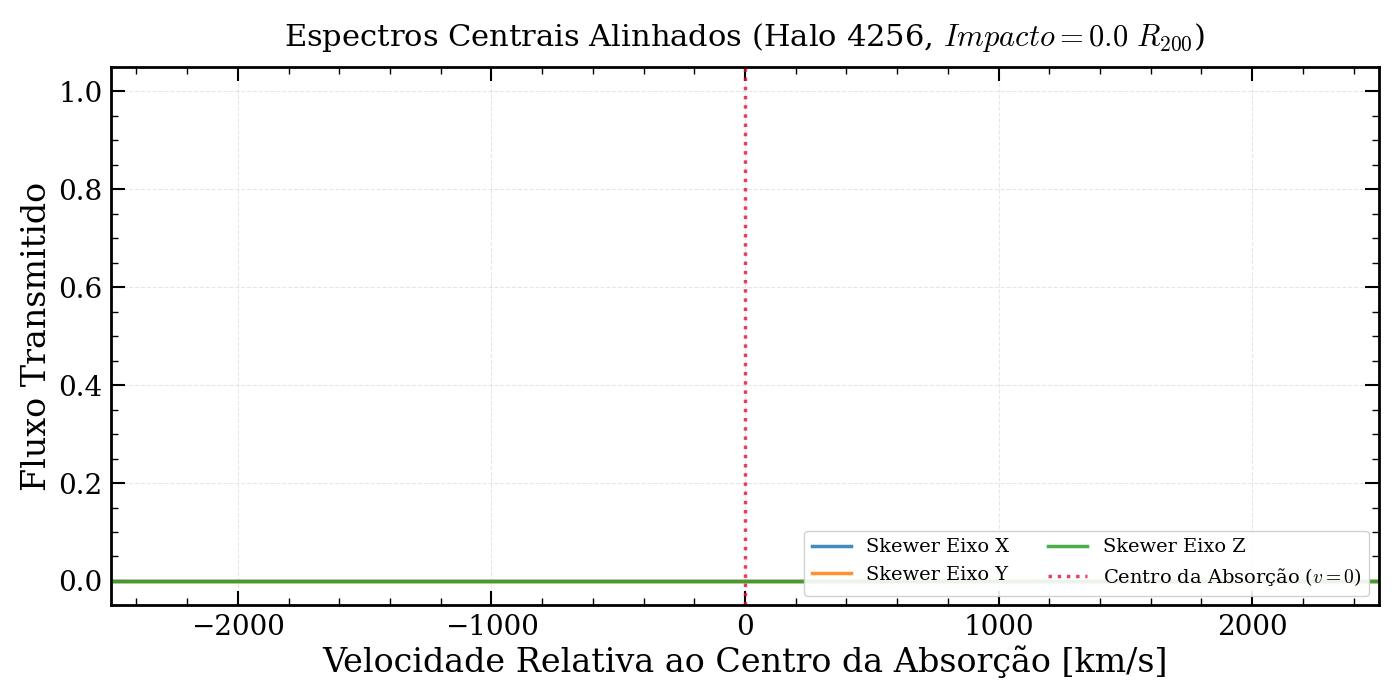

/tmp/ipykernel_989589/503246214.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  skewers_to_plot = df_r.groupby('axis').apply(lambda x: x.sample(n=2, random_state=42)).reset_index(drop=True)
/tmp/ipykernel_989589/503246214.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  skewers_to_plot = df_r.groupby('axis').apply(lambda x: x.sample(n=2, random_state=42)).reset_index(drop=True)
/tmp/ipykernel_989589/503246

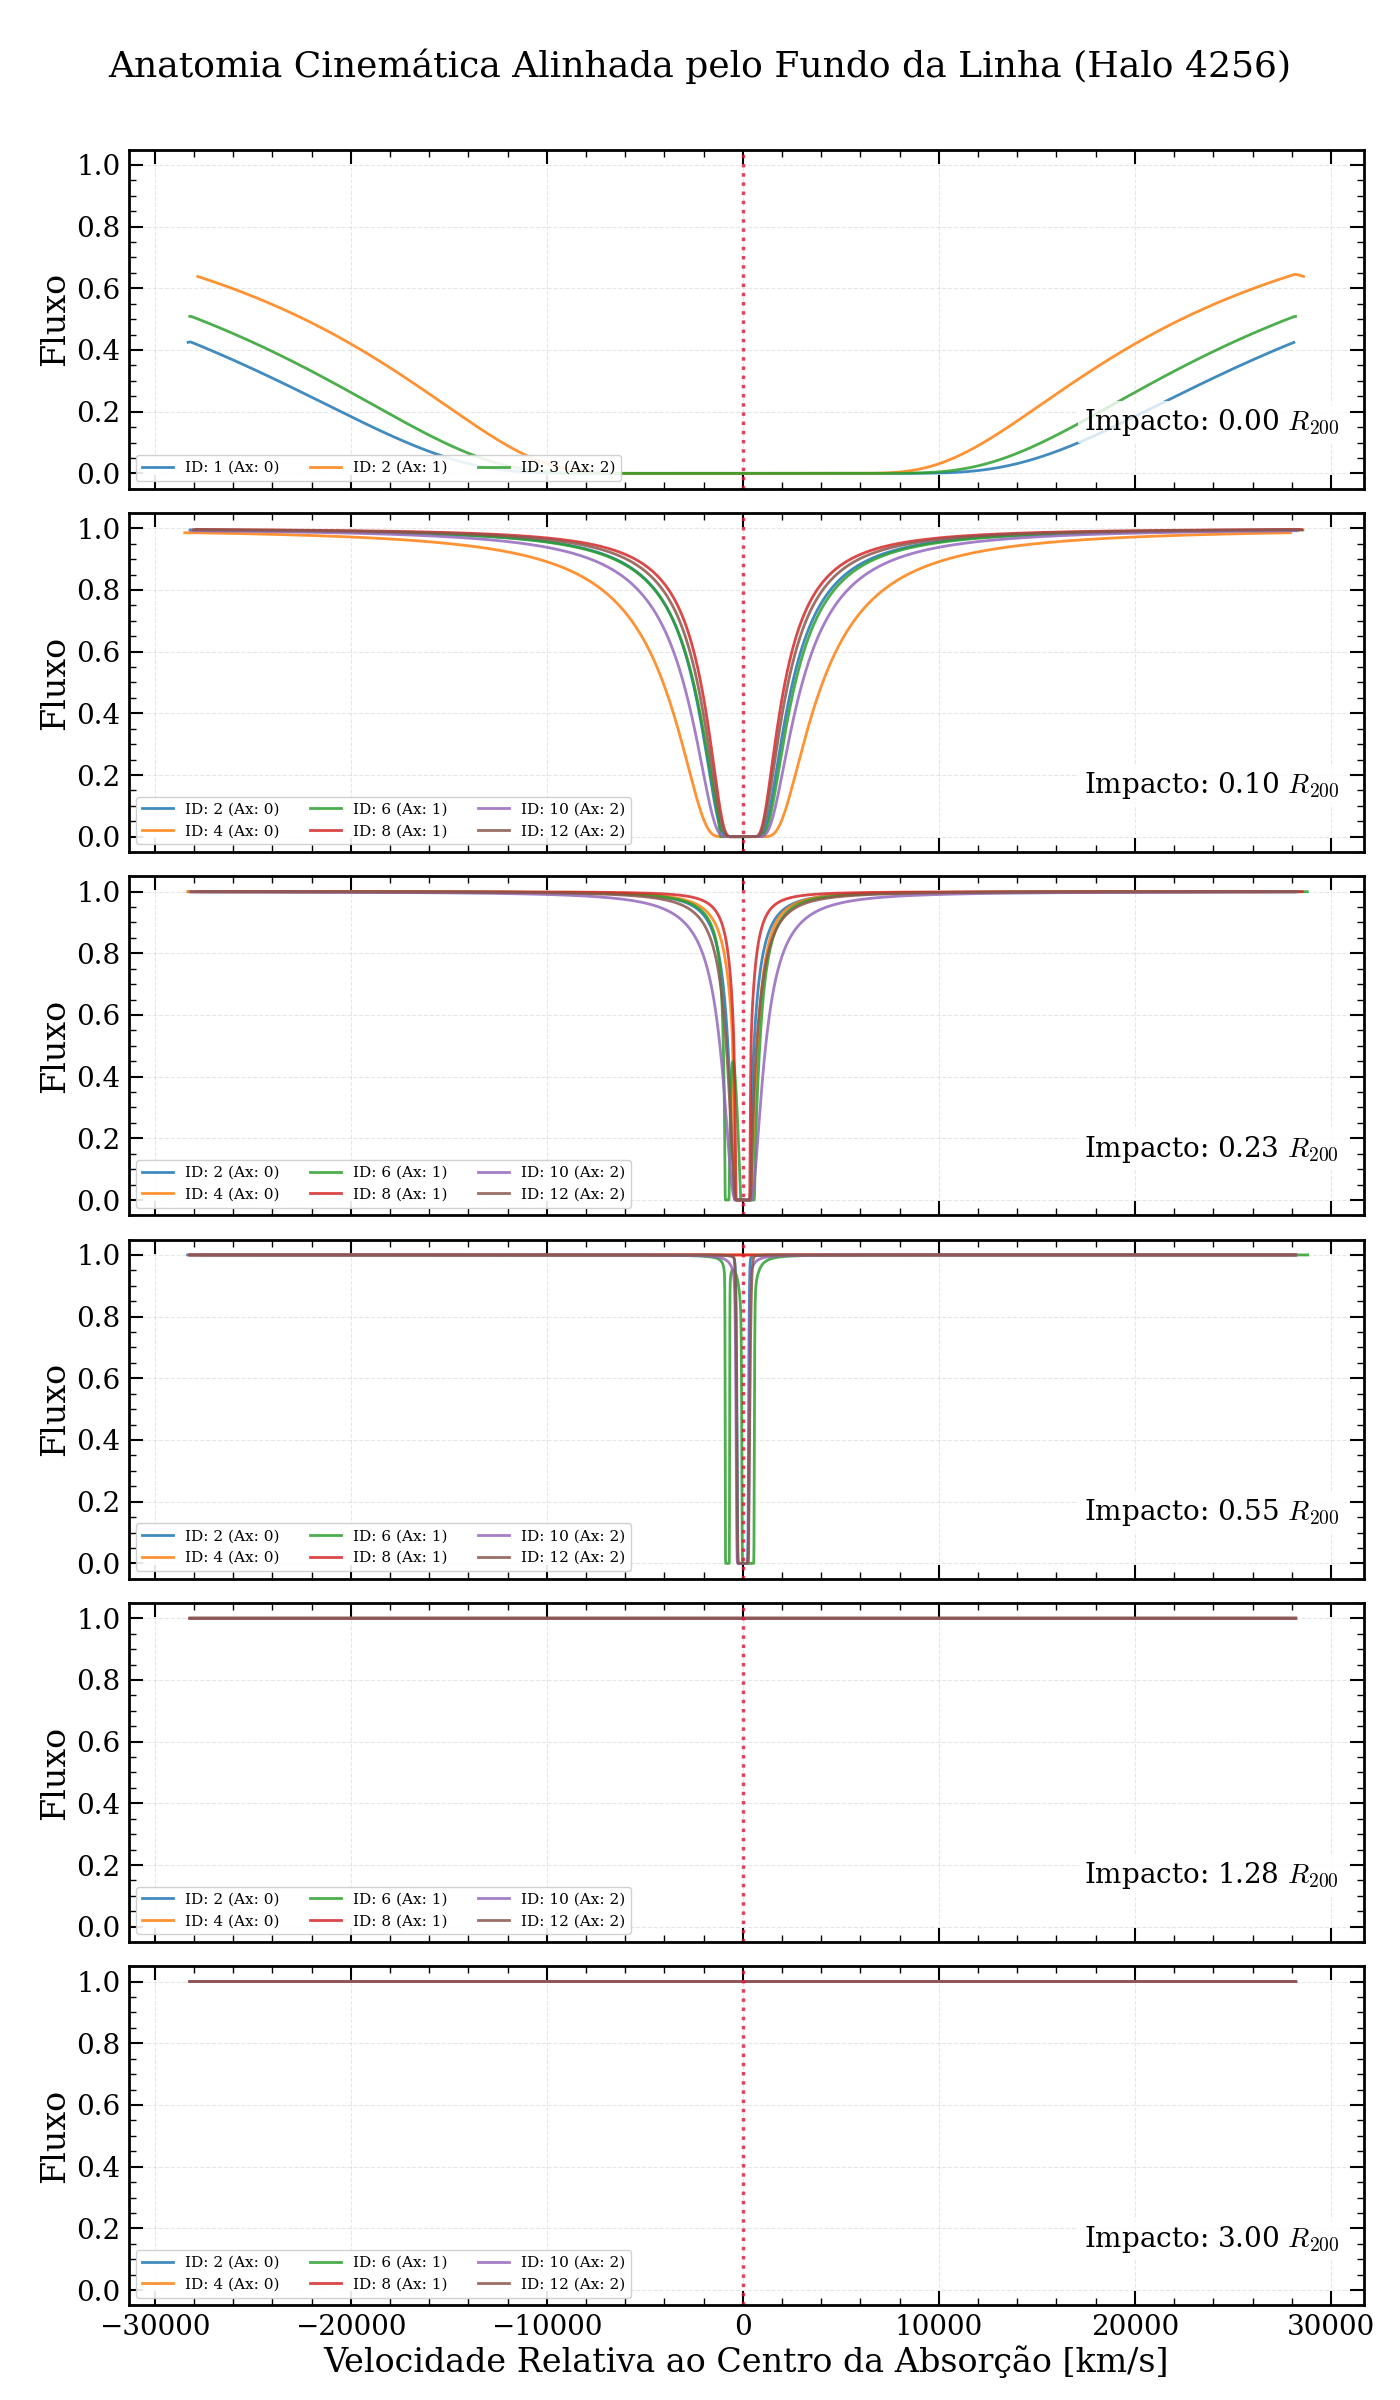

In [2]:
%matplotlib widget 
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Caminho para o arquivo que acabou de ser gerado
file_path = '/home/vroberto/FakeSpectra_DLAs/notebooks/fiducial_1Halos_DLAMode_FullMap.pkl'
df = pd.read_pickle(file_path)

# --- CONFIGURAÇÃO DE ESTILO ---
def matplotlib_default_config():
    font = {'family' : 'serif', 'weight' : 'normal', 'size'   : 14}
    rcnew = {
        "mathtext.fontset" : "cm", "text.usetex": False, 'figure.frameon': True,
        'axes.linewidth': 2., "axes.titlesize" : 24, "axes.labelsize" : 24,
        "legend.fontsize" : 14, 'legend.fancybox': True, 'lines.linewidth': 2.0,
        'xtick.alignment': 'center', 'xtick.bottom': True, 'xtick.color': 'black',
        'xtick.direction': 'in', 'xtick.labelbottom': True, 'xtick.labelsize': 20,
        'xtick.major.bottom': True, 'xtick.major.pad': 6.0, 'xtick.major.size': 10.0,
        'xtick.major.width': 1.5, 'xtick.minor.bottom': True, 'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0, 'xtick.minor.visible': True, 'xtick.minor.width': 1.0,
        'xtick.top': True, 'ytick.alignment': 'center_baseline', 'ytick.color': 'black',
        'ytick.direction': 'in', 'ytick.labelleft': True, 'ytick.labelsize': 20,
        'ytick.left': True, 'ytick.major.left': True, 'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0, 'ytick.major.width': 1.5, 'ytick.minor.left': True,
        'ytick.minor.pad': 3.4, 'ytick.minor.right': True, 'ytick.minor.size': 5.0,
        'ytick.minor.visible': True, 'ytick.minor.width': 1.0, 'ytick.right': True
    }
    return font, rcnew

font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

# --- A NOVA FUNÇÃO DE CENTRALIZAÇÃO GEOMÉTRICA ---
def align_to_absorption_center(vel_array, flux_array):
    """
    Encontra o centro real da absorção. Em vez de pegar apenas um ponto mínimo,
    ele pega todo o "fundo" saturado da linha e calcula o ponto médio perfeito.
    """
    min_flux = np.min(flux_array)
    
    # Tolerância de 2% acima do mínimo para pegar toda a extensão do fundo do poço
    threshold = min_flux + 0.02 
    
    # Encontra todos os índices que formam o fundo do DLA
    bottom_indices = np.where(flux_array <= threshold)[0]
    
    # O centro cinemático real é a média das velocidades dessa região achatada
    v_center = np.mean(vel_array[bottom_indices])
    
    vel_aligned = vel_array - v_center
    return vel_aligned, v_center


# ==============================================================================
# LÓGICA DO PLOT 1: SKEWERS CENTRAIS ALINHADOS
# ==============================================================================
df_center = df[np.isclose(df['r_multiplier'], 0.0)].copy()
df_center = df_center.sort_values(by='axis')

fig, ax = plt.subplots(figsize=(14, 7))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c'] 
eixos_nomes = ['X', 'Y', 'Z']

for (idx, row), color, eixo in zip(df_center.iterrows(), colors, eixos_nomes):
    # Aplica o novo alinhamento inteligente
    vel_aligned, shift = align_to_absorption_center(row['vel_axis'], row['flux'])
    ax.plot(vel_aligned, row['flux'], lw=2.5, alpha=0.85, color=color, label=f"Skewer Eixo {eixo}")
    
ax.axvline(0.0, color='crimson', linestyle=':', lw=2.5, alpha=0.8, label='Centro da Absorção ($v=0$)')

ax.set_ylabel('Fluxo Transmitido')
ax.set_xlabel(r'Velocidade Relativa ao Centro da Absorção [km/s]')
ax.set_ylim(-0.05, 1.05)

# TRAVANDO O ZOOM PARA AS BARRIGAS NÃO FICAREM FINAS
ax.set_xlim(-2500, 2500) 

ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='lower right', fontsize=14, framealpha=0.9, ncol=2)

halo_id_title = df_center['halo_id'].iloc[0]
plt.title(f"Espectros Centrais Alinhados (Halo {halo_id_title}, $Impacto = 0.0 \ R_{{200}}$)", fontsize=22, pad=15)

plt.tight_layout()
plt.show()


# ==============================================================================
# LÓGICA DO PLOT 2: STACKED SPECTRA BY IMPACT PARAMETER
# ==============================================================================
r_mults = sorted(df['r_multiplier'].unique())
fig2, axes2 = plt.subplots(nrows=6, ncols=1, figsize=(14, 24), sharex=True)
colors_stacked = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

for i, r in enumerate(r_mults):
    ax = axes2[i]
    df_r = df[np.isclose(df['r_multiplier'], r)].copy()
    
    if np.isclose(r, 0.0):
        skewers_to_plot = df_r.sort_values(by='axis')
    else:
        # Pega 2 amostras de cada eixo (X, Y, Z) para totalizar 6
        skewers_to_plot = df_r.groupby('axis').apply(lambda x: x.sample(n=2, random_state=42)).reset_index(drop=True)
    
    for j, (idx, row) in enumerate(skewers_to_plot.iterrows()):
        # Aplica o novo alinhamento inteligente
        vel_aligned, shift = align_to_absorption_center(row['vel_axis'], row['flux'])
        
        ax.plot(
            vel_aligned, row['flux'], alpha=0.85, 
            color=colors_stacked[j % len(colors_stacked)], 
            label=f"ID: {int(row['skewer_id'])} (Ax: {int(row['axis'])})"
        )
        
    ax.axvline(0.0, color='crimson', linestyle=':', lw=2.5, alpha=0.8)
    ax.text(0.98, 0.15, f"Impacto: {r:.2f} $R_{{200}}$", transform=ax.transAxes, 
            fontsize=20, ha='right', va='bottom', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
    
    ax.set_ylabel('Fluxo')
    ax.set_ylim(-0.05, 1.05)
    

    
    ax.grid(True, alpha=0.3, linestyle='--')
    ncol_legend = 3 if len(skewers_to_plot) > 3 else len(skewers_to_plot)
    ax.legend(loc='lower left', fontsize=11, ncol=ncol_legend, framealpha=0.9)

axes2[-1].set_xlabel(r'Velocidade Relativa ao Centro da Absorção [km/s]')
plt.suptitle(f"Anatomia Cinemática Alinhada pelo Fundo da Linha (Halo {halo_id_title})", fontsize=26, y=0.98)

plt.subplots_adjust(hspace=0.05)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()